In [40]:
import pandas as pd
import re
import nltk
nltk.download("stopwords")
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet')
import string
from collections import Counter
import seaborn as sns
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Fahad\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Fahad\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [12]:
dataset = pd.read_csv("./fake_news_dataset.csv")
print("First 10:\n", dataset.head(10), "\nShape: ", dataset.shape, "\nNull Count:\n", dataset.isnull().sum(), "\nDistribution:\n", dataset['label'].value_counts(), "\n5 text examples:\n", dataset.sample(5, random_state=42))


First 10:
                                                 Text label
0   Top Trump Surrogate BRUTALLY Stabs Him In The...  Fake
1  U.S. conservative leader optimistic of common ...  Real
2  Trump proposes U.S. tax overhaul, stirs concer...  Real
3   Court Forces Ohio To Allow Millions Of Illega...  Fake
4  Democrats say Trump agrees to work on immigrat...  Real
5  France says pressure needed to stop North Kore...  Real
6  Trump on Twitter (August 8): Opioid crisis, No...  Real
7   BUSTED: Trump Supporter Used Poll Watcher Cre...  Fake
8  Fatal Niger operation sparks calls for public ...  Real
9  Trump says he has 'great heart' for immigrant ...  Real 
Shape:  (9900, 2) 
Null Count:
 Text     0
label    0
dtype: int64 
Distribution:
 label
Fake    5000
Real    4900
Name: count, dtype: int64 
5 text examples:
                                                    Text label
8432   Trump’s Involvement In Houston Chemical Plant...  Fake
5680  U.S. Senate votes near unanimously for Russia,...

In [13]:
HTML_TAG = re.compile(r"<.*?>")
URL = re.compile(r"https?://\S+|www\.\S+")
NUM_RE = re.compile(r"\d+")
ALPHABET_RE = re.compile(r"[^a-z\s]")
STOPWORDS = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text: str) -> str:
    text = text.lower()
    text = HTML_TAG.sub(' ', text)
    text = URL.sub(' ', text)
    text = NUM_RE.sub(' ', text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = ALPHABET_RE.sub(' ', text)
    
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t not in STOPWORDS and len(t) > 2]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    
    return ' '.join(tokens)

In [14]:
dataset['cleaned_text'] = dataset["Text"].apply(clean_text)

In [15]:
display(dataset[['Text', 'cleaned_text']].sample(10, random_state=42).rename(columns={'text': 'original_text'}))

,Text,cleaned_text
8432,Trump’s Involvement In Houston Chemical Plant...,trump involvement houston chemical plant explo...
5680,"U.S. Senate votes near unanimously for Russia,...",senate vote near unanimously russia iran sanct...
4767,White and male: broader bureaucracy mirrors Tr...,white male broader bureaucracy mirror trump ca...
9218,"Trump, Modi call North Korea's 'grave threat' ...",trump modi call north korea grave threat peace...
621,"Ivanka Trump Shares Famous Jewish Quote, But ...",ivanka trump share famous jewish quote hilario...
3429,Trump open to signing Russia sanctions legisla...,trump open signing russia sanction legislation...
9350,"Jeff Sessions: Oh, You Mean THAT Russian Cont...",jeff session mean russian contact remember att...
5960,WATCH: Joy Reid Shuts Down Trump Supporter’s ...,watch joy reid shuts trump supporter bizarre e...
8185,Staffers INSIDE The White House Are Showing U...,staffer inside white house showing massive tru...
9841,Ex-CIA chief: Worries grew of Trump campaign c...,excia chief worry grew trump campaign contact ...


In [16]:
def word_count(input):
    return len(input.split()) if isinstance(input, str) else 0

def char_count(input):
    return len(input) if isinstance(input, str) else 0

dataset['word_count'] = dataset['cleaned_text'].apply(word_count)
dataset['char_count'] = dataset['cleaned_text'].apply(char_count)

print("Average Word Count: ", dataset["word_count"].mean())
print("Average Character Count: ", dataset["char_count"].mean())

Average Word Count:  236.79030303030302
Average Character Count:  1769.6857575757576


In [17]:
words = " ".join(dataset['cleaned_text']).split()
frequency = Counter(words)
top_words = frequency.most_common(50)
common_dataframe = pd.DataFrame(top_words, columns = ['word', "count"])
display(common_dataframe.head(10))

,word,count
0,trump,59961
1,said,28993
2,president,16037
3,would,14728
4,republican,14228
5,state,12384
6,house,12125
7,donald,11635
8,people,9814
9,white,8943


In [18]:
def ngrams(tokens, n):
    return [" ".join(tokens[i:i+n]) for i in range(len(tokens) - n + 1)]

bigrams = Counter(ngrams(words, 2))
trigrams = Counter(ngrams(words, 3))

common_bi = pd.DataFrame(bigrams.most_common(20), columns=["word", "count"])
common_tri = pd.DataFrame(trigrams.most_common(20), columns=["word", "count"])

print("Common Bigrams:")
display(common_bi.head(20))
print("Common Trigrams:")
display(common_tri.head(20))



Common Bigrams:


,word,count
0,donald trump,10794
1,white house,6775
2,united state,4564
3,president donald,3625
4,image via,3455
5,washington reuters,2978
6,trump administration,2156
7,new york,2107
8,hillary clinton,1901
9,trump said,1820


Common Trigrams:


,word,count
0,president donald trump,3617
1,donald trump realdonaldtrump,1210
2,reuters president donald,1004
3,president barack obama,933
4,washington reuters president,748
5,new york time,614
6,affordable care act,547
7,former president barack,509
8,via getty image,504
9,featured image via,430


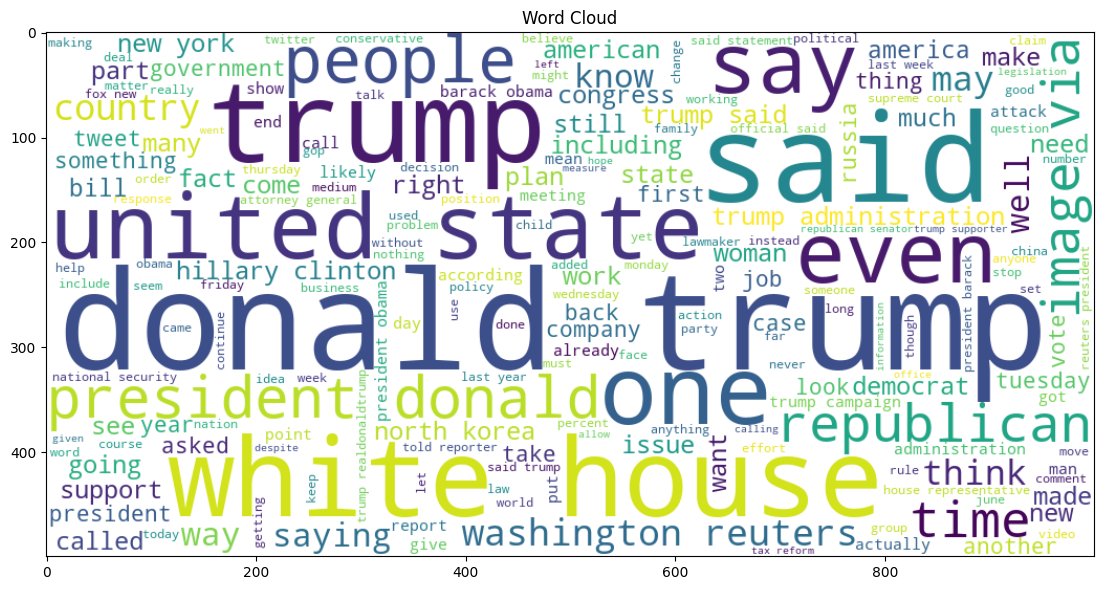

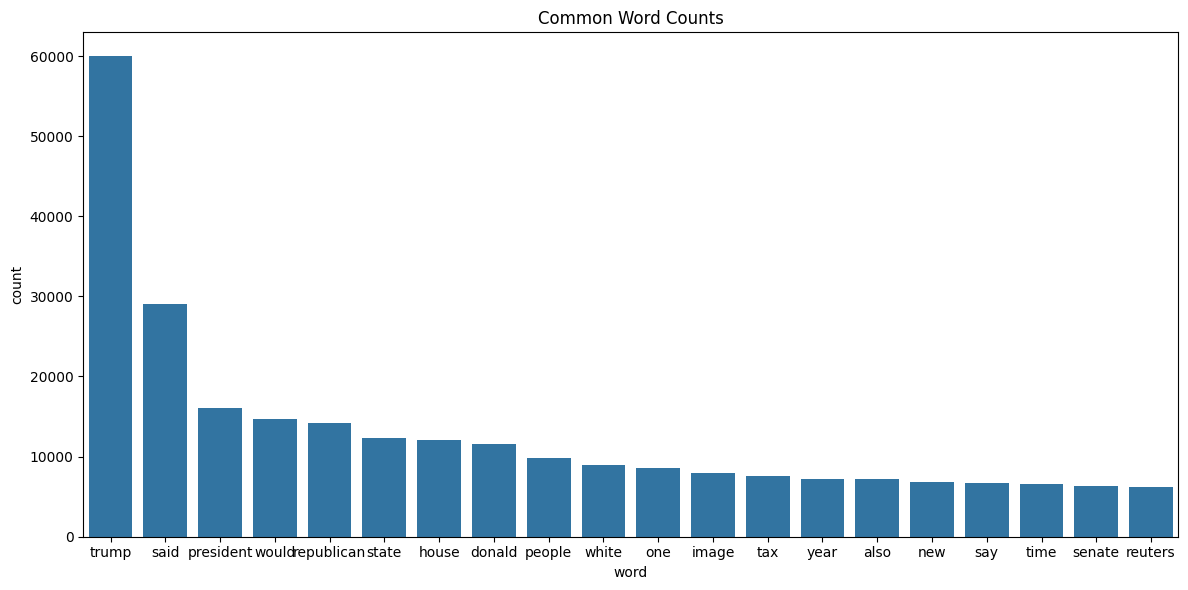

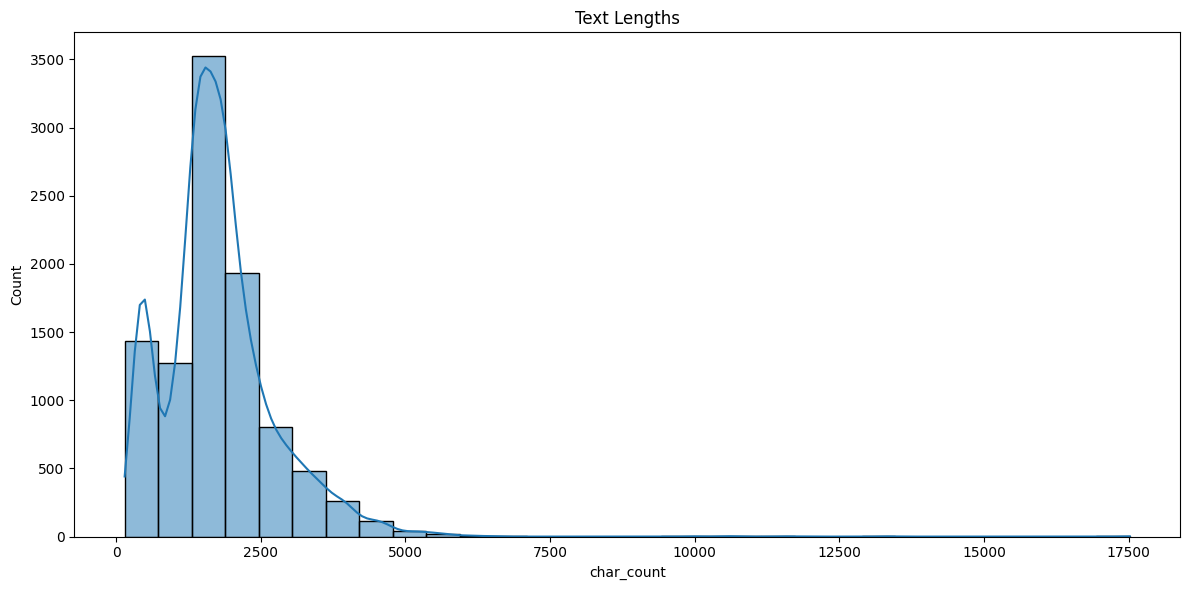

In [25]:
text = " ".join(dataset["cleaned_text"])
wc = WordCloud(width=1000, height = 500, background_color = "white", max_words = 200).generate(text)


plt.figure(figsize=(12,6))
plt.title("Word Cloud")
plt.imshow(wc, interpolation="bilinear")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,6))
plt.title("Common Word Counts")
sns.barplot(x="word", y="count", data=common_dataframe.head(20))
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,6))
plt.title("Text Lengths")
sns.histplot(dataset["char_count"], bins=30, kde=True)
plt.tight_layout()
plt.show()

In [50]:
insights = [
    "The data Seems to be focused on the political aspect of USA",
    "The data heavily focuses on circumstances related with the President Donald Trump and Hillary Clinton (The competition)",
    "Bigrams like 'White House' and 'north Korea' capture useful contextual cues that single words miss.",
    "The word count distribution is left-skewed",
    "The sentiment labels seem to be fairly balanced making the dataset suitable"
]
for i, s in enumerate(insights, 1):
    print(f"Insight {i}: {s}")


Insight 1: The data Seems to be focused on the political aspect of USA
Insight 2: The data heavily focuses on circumstances related with the President Donald Trump and Hillary Clinton (The competition)
Insight 3: Bigrams like 'White House' and 'north Korea' capture useful contextual cues that single words miss.
Insight 4: The word count distribution is left-skewed
Insight 5: The sentiment labels seem to be fairly balanced making the dataset suitable


In [28]:
bow_vectorizer = CountVectorizer(max_features=20000)
bow = bow_vectorizer.fit_transform(dataset["cleaned_text"])

tfidf_vectorizer = TfidfVectorizer(max_features=20000)
tfidf = tfidf_vectorizer.fit_transform(dataset["cleaned_text"])

print("Bag of Words Shape: ", bow.shape)
print("TF-IDF Shape: ", tfidf.shape)


Bag of Words Shape:  (9900, 20000)
TF-IDF Shape:  (9900, 20000)


In [31]:
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())
max_scores = tfidf.max(axis=0).toarray().ravel()
top_idf = np.argsort(max_scores)[-15:][::-1]
this_dataframe = pd.DataFrame({"word": feature_names[top_idf], "score": max_scores[top_idf]})
display(this_dataframe)

,word,score
0,phoenixnewtimes,0.921205
1,pavarotti,0.887763
2,merriamwebster,0.885306
3,cher,0.880906
4,petrov,0.878952
5,npr,0.877473
6,cuban,0.865346
7,ellison,0.857859
8,tinytrump,0.854690
9,trumphotels,0.853624


In [51]:
print("\nTF-IDF typically surpasses Bag of Words when:")
print("Documents contain many common words. We can focus on the important words")
print("You need to capture term specificity across documents rather than raw frequency.")
print("The document collection is heterogeneous and you wantf features that relect discriminative power rather than count alone.")


TF-IDF typically surpasses Bag of Words when:
Documents contain many common words. We can focus on the important words
You need to capture term specificity across documents rather than raw frequency.
The document collection is heterogeneous and you wantf features that relect discriminative power rather than count alone.


Logistic Regression Classification Report:
               precision    recall  f1-score   support

        Fake       0.99      0.99      0.99      1000
        Real       0.99      0.99      0.99       980

    accuracy                           0.99      1980
   macro avg       0.99      0.99      0.99      1980
weighted avg       0.99      0.99      0.99      1980



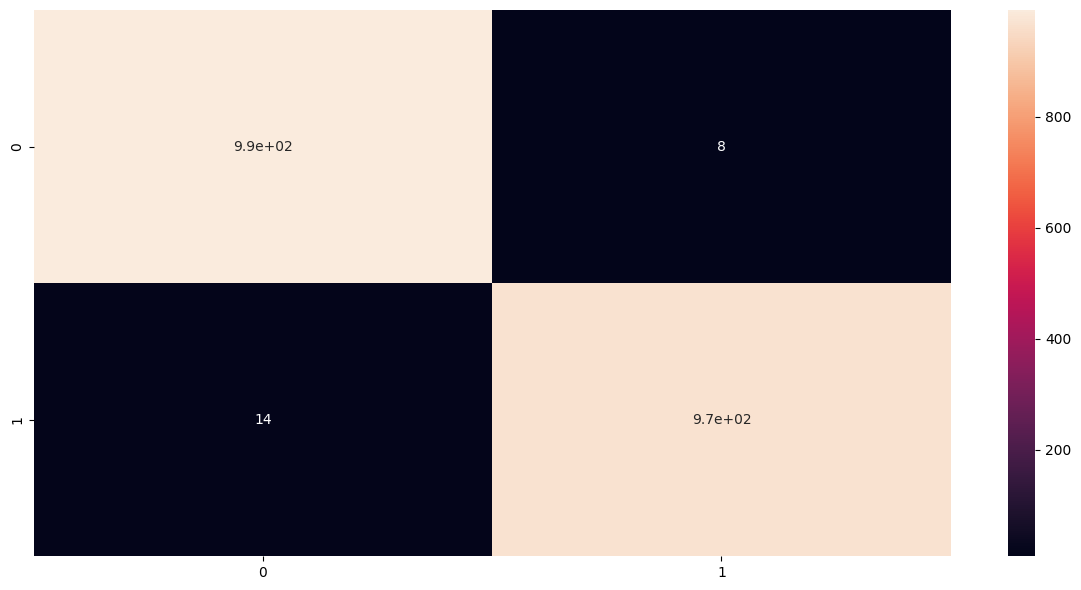

Naive Bayes Classification Report:
               precision    recall  f1-score   support

        Fake       0.96      0.95      0.96      1000
        Real       0.95      0.96      0.96       980

    accuracy                           0.96      1980
   macro avg       0.96      0.96      0.96      1980
weighted avg       0.96      0.96      0.96      1980



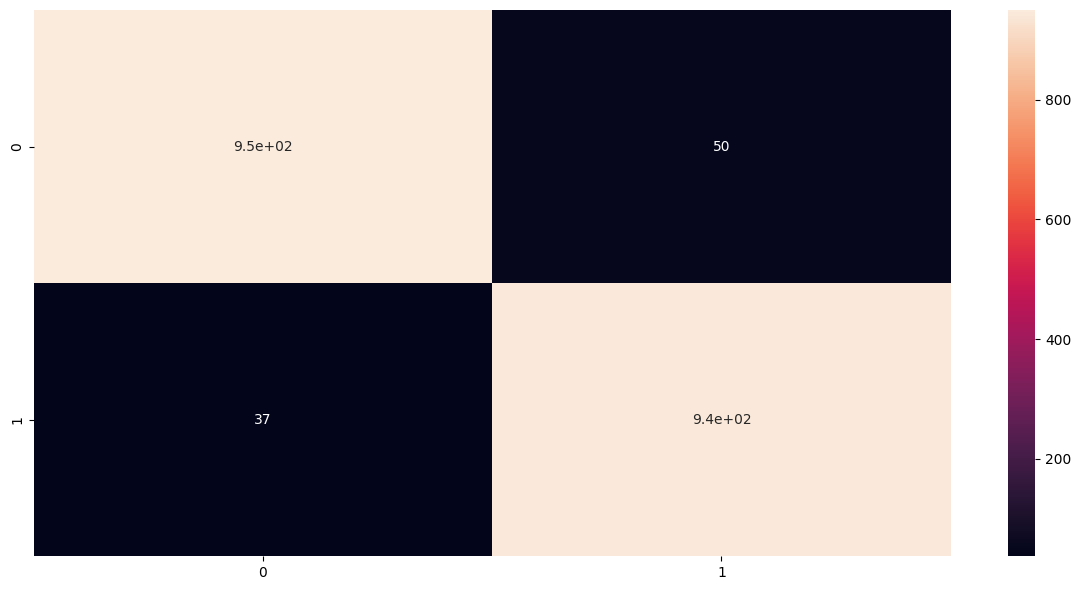

SVM Classification Report:
               precision    recall  f1-score   support

        Fake       0.99      1.00      0.99      1000
        Real       1.00      0.99      0.99       980

    accuracy                           0.99      1980
   macro avg       0.99      0.99      0.99      1980
weighted avg       0.99      0.99      0.99      1980



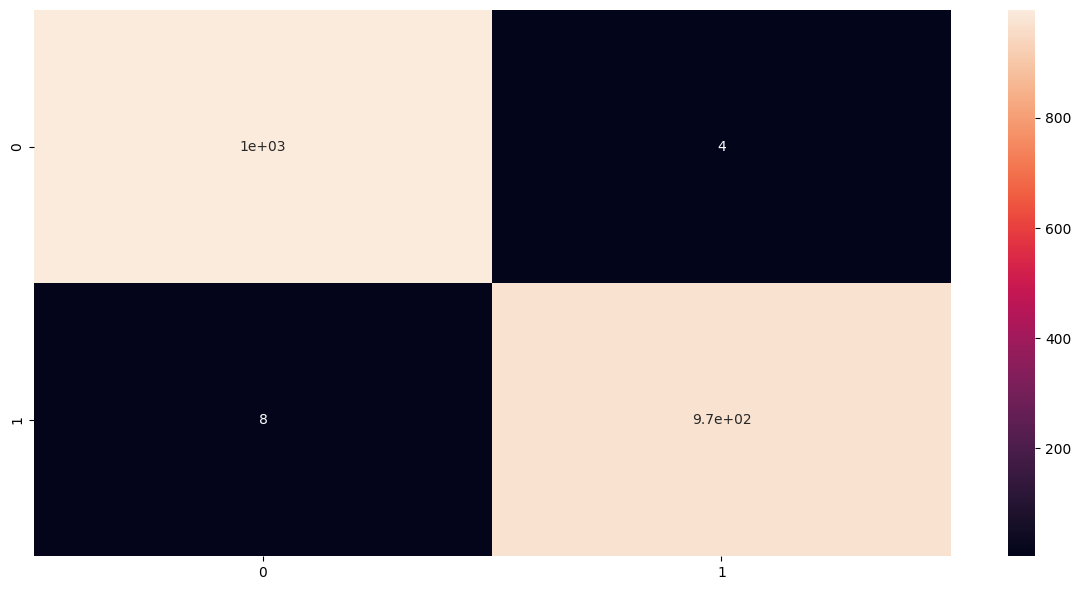

In [39]:
y = dataset["label"]

x_train, x_test, y_train, y_test = train_test_split(tfidf, y, test_size = 0.2, random_state=42, stratify=y)

def evaluate_model(x_test, y_test, model, name="model"):
    result = model.predict(x_test)
    print(f"{name} Classification Report:\n", classification_report(y_test, result))
    plt.figure(figsize=(12, 6))
    sns.heatmap(confusion_matrix(y_test, result), annot=True)
    plt.tight_layout()
    plt.show()


logistic = LogisticRegression(max_iter=1000)
l_model = logistic.fit(x_train, y_train)
evaluate_model(x_test, y_test, l_model, name="Logistic Regression")

naive = MultinomialNB()
n_model = naive.fit(x_train, y_train)
evaluate_model(x_test, y_test, n_model, name="Naive Bayes")

support = SVC()
s_model = support.fit(x_train, y_train)
evaluate_model(x_test, y_test, s_model, name="SVM")



In [53]:
interpretations = [
    "Logistic Regression: Excellent results which are comparable to SVM",
    "Naive Bayes: The worst performing model according to the metrics",
    "Linear SVM: Performs similar to logistic regression but has some less misclassifications as seen by the confusion matrix and Recall, Precision"
]
for interp in interpretations:
    print(interp)

Logistic Regression: Excellent results which are comparable to SVM
Naive Bayes: The worst performing model according to the metrics
Linear SVM: Performs similar to logistic regression but has some less misclassifications as seen by the confusion matrix and Recall, Precision


In [41]:
class TextCleaner(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): 
        return self
    def transform(self, X):
        return pd.Series(X).apply(clean_text).values


predict_pipeline = Pipeline([
    ('cleaner', TextCleaner()),
    ('vectorizer', tfidf_vectorizer),
    ('model', s_model)
])

def predict_sentiment(texts):
    preds = predict_pipeline.predict(texts if isinstance(texts, (list, pd.Series)) else [texts])
    return preds

In [47]:
n = int(input("How many sentences do you want to test? "))

test_sentences = []
for i in range(n):
    sentence = input(f"Enter sentence {i+1}: ")
    test_sentences.append(sentence)

predictions = predict_sentiment(test_sentences)

for s, p in zip(test_sentences, predictions):
    print(f"Text: {s}\nPredicted Sentiment: {p}\n---")

Text: President Trump is an illegal immigrant
Predicted Sentiment: Real
---
Text: President Trump is a President
Predicted Sentiment: Real
---


In [48]:
import joblib

joblib.dump(l_model, "l_model.pkl")
joblib.dump(s_model, "s_model.pkl")
joblib.dump(n_model, "n_model.pkl")

joblib.dump(tfidf_vectorizer, "vectorizer.pkl")

joblib.dump(TextCleaner(), "cleaner.pkl")

print("Exported models and vectorizers")


Exported models and vectorizers


In [57]:
print("Preprocessing")
print("Cleaning out URLs really helped they were just noise and didn't add anything useful.")
print("Removing punctuation was a mixed bag: it simplified the text, but it also blurred the line between Twitter handles (@username) and normal words, which reduced differentiation.")

print("\nModel Performance")
print("Logistic Regression: Very good results. Comparable with SVM.")
print("Naive Bayes: Weakest. The metrics showed it lagging behind.")
print("Linear SVM: Similar to Logistic Regression, but with slightly fewer misclassifications confusion matrix and precision/recall looked a bit cleaner.")

print("\nData Insights")
print("The dataset is heavily tilted toward US politics, especially around Donald Trump and Hillary Clinton.")
print("Common bigrams like 'White House' and 'north Korea' show that context matters single words don't capture the full meaning.")
print("Word count distribution is left-skewed: lots of short texts, fewer long ones.")
print("Sentiment labels are fairly balanced, which makes the dataset suitable for training without heavy rebalancing.")

print("\nTest Predictions")
print("'President Trump is an illegal immigrant' -> Predicted Sentiment: Real")
print("'President Trump is a President' -> Predicted Sentiment: Real")
print("This shows the model is treating these statements as factual/real rather than picking up on sentiment, reflecting its political context focus.")

print("\nKey Takeaways")
print("Preprocessing choices really matter: removing URLs was a win, but punctuation removal needs caution depending on the platform (Twitter vs. plain text).")
print("Logistic Regression and SVM are the go-to models. Naive Bayes struggles with this kind of data.")
print("The dataset is political in nature, so the model's 'sentiment' predictions lean toward real vs. fake/valid vs. invalid statements rather than emotional positivity/negativity.")
print("Contextual features (like bigrams) add a lot of value they capture meaning that single words miss.")

Preprocessing
Cleaning out URLs really helped they were just noise and didn't add anything useful.
Removing punctuation was a mixed bag: it simplified the text, but it also blurred the line between Twitter handles (@username) and normal words, which reduced differentiation.

Model Performance
Logistic Regression: Very good results. Comparable with SVM.
Naive Bayes: Weakest. The metrics showed it lagging behind.
Linear SVM: Similar to Logistic Regression, but with slightly fewer misclassifications confusion matrix and precision/recall looked a bit cleaner.

Data Insights
The dataset is heavily tilted toward US politics, especially around Donald Trump and Hillary Clinton.
Common bigrams like 'White House' and 'north Korea' show that context matters single words don't capture the full meaning.
Word count distribution is left-skewed: lots of short texts, fewer long ones.
Sentiment labels are fairly balanced, which makes the dataset suitable for training without heavy rebalancing.

Test Pre